# Importance scores across every axis, before any pruning

Part of plan.md step 1.3's GPU-dependent validation, extended into a full
multi-axis view rather than a spot-check: real forward hooks against
`Qwen3-30B-A3B-Base` (bf16), run over 48 samples from the pinned TypeScript
calibration shard (`configs/qwen3-30b-a3b.toml`, shard 0 of 71). This is
purely observational -- no layer, head, or expert has been pruned. The
point is to see what the real data says is important *before* Phase 2 makes
any pruning decision, and to make that visible to anyone reading this
project, not just whoever ran the script.

Three axes, three different formulas (deliberately -- see `bonsai.importance`'s
own docstring for why depth doesn't share code with heads/experts):

- **Attention heads** (`bonsai.importance.head_importance`): 2407.14679
  Section 2.2's `F_head` -- per-head output-vector L2 norm, aggregated over
  every token.
- **Experts** (`bonsai.importance.expert_importance`): gate-weighted
  expert-output norm, averaged only over each expert's routed tokens (REAP,
  arXiv 2510.13999; independently, NVIDIA Model-Optimizer's Minitron-MoE
  extension converges on the same formula).
- **Depth** (`bonsai.importance.depth.block_importance`): 2408.11796's Block
  Importance -- `1 - cosine_similarity(layer_input, layer_output)`, a
  single-forward-pass proxy for how much a layer actually transforms its
  input.

The actual GPU forward pass and hook wiring lives in a throwaway script, not
here -- same reasoning plan.md already gives for step 1.3 having no notebook
of its own: the hook/monkey-patch machinery isn't something worth reading,
the *scores* are. This notebook loads the saved tensors and visualizes them.

In [1]:
import torch

RUN_DIR = "../runs/20260919T150941Z-ff00be-importance-scores"
data = torch.load(f"{RUN_DIR}/importance-scores.pt", weights_only=True)

head_scores = data["head_scores"]
expert_scores = data["expert_scores"]
depth_scores = data["depth_scores"]

print(
    f"{data['num_layers']} layers, {data['num_heads']} heads/layer, {data['num_experts']} experts/layer"
)
print(f"{data['num_samples']} calibration samples, mean length {data['mean_length']:.0f} tokens")
print()
print(
    f"head_scores   {tuple(head_scores.shape)}  min={head_scores.min():.2f}  max={head_scores.max():.2f}"
)
print(
    f"expert_scores {tuple(expert_scores.shape)} min={expert_scores.min():.2f}  max={expert_scores.max():.2f}"
)
print(
    f"depth_scores  {tuple(depth_scores.shape)}    min={depth_scores.min():.4f} max={depth_scores.max():.4f}"
)

48 layers, 32 heads/layer, 128 experts/layer
48 calibration samples, mean length 177 tokens

head_scores   (48, 32)  min=2.39  max=967.72
expert_scores (48, 128) min=0.00  max=191.59
depth_scores  (48,)    min=0.0111 max=0.4881


## Attention heads

One score per (layer, head), from real attention output activations --
bigger means that head's output carries more magnitude across the
calibration set, the same signal 2407.14679 uses to decide which heads
survive width pruning (step 2.2).

highest-scoring head overall: layer 47, head 18 (score 967.72)


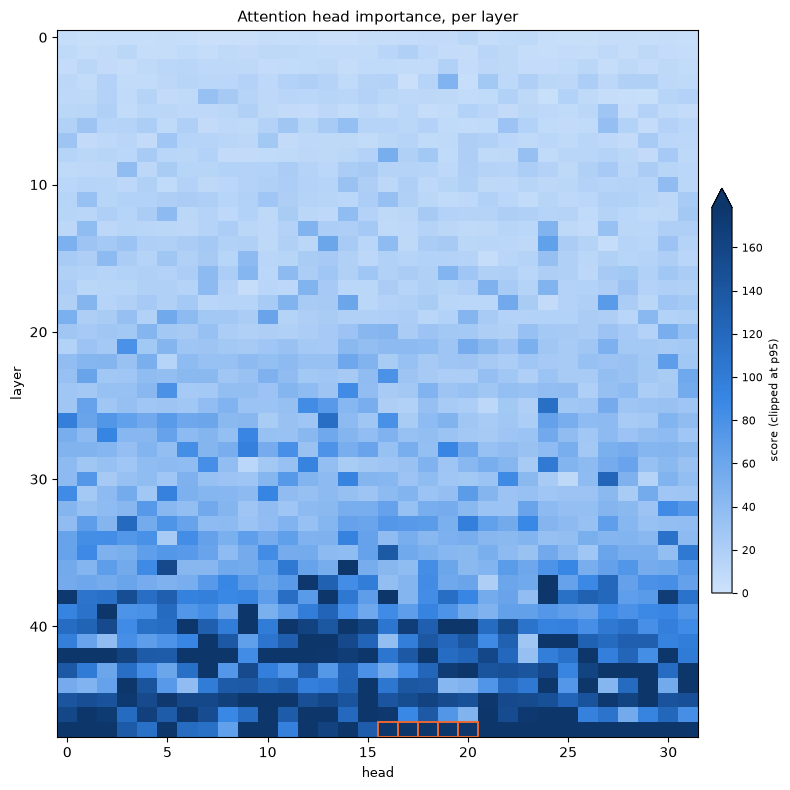

In [2]:
from bonsai.importance.viz import plot_head_heatmap

fig = plot_head_heatmap(head_scores)
fig.savefig(f"{RUN_DIR}/head_heatmap.png", dpi=150)

layer_idx, head_idx = divmod(int(head_scores.argmax()), head_scores.shape[1])
print(
    f"highest-scoring head overall: layer {layer_idx}, head {head_idx} (score {head_scores.max():.2f})"
)

## Experts

One score per (layer, expert), gate-weighted output norm over each expert's
own routed tokens -- deliberately not a simple magnitude average, since an
expert that's rarely selected but produces a large output when it is
shouldn't be scored the same as one that's never useful.

arXiv 2507.23279 reports three specific "Super Experts" in this exact model
-- layer 1/expert 68, layer 2/expert 92, layer 3/expert 82 -- whose rare,
massive outputs anchor attention sinks; deleting them alone measured a
WikiText-2 PPL jump from 8.70 to 59.86 in that paper. 1.3's sanity check
already confirmed these three rank #1 in their layer on a smaller (24-sample)
run; the cell below checks the same claim against this full 48-layer,
48-sample collection.

layer 1, expert 68: score=78.22  rank=0/128 (0 = highest-scoring expert in that layer)
layer 2, expert 92: score=56.44  rank=0/128 (0 = highest-scoring expert in that layer)
layer 3, expert 82: score=50.62  rank=0/128 (0 = highest-scoring expert in that layer)


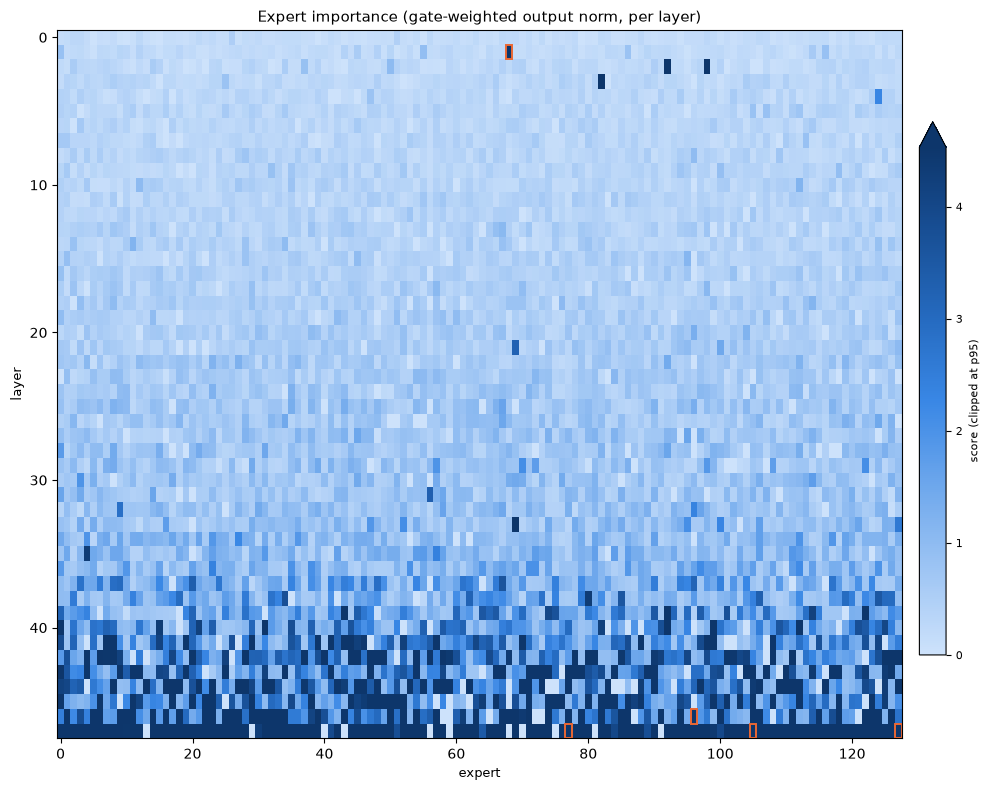

In [3]:
from bonsai.importance.viz import plot_expert_heatmap

fig = plot_expert_heatmap(expert_scores)
fig.savefig(f"{RUN_DIR}/expert_heatmap.png", dpi=150)

for layer, expert in [(1, 68), (2, 92), (3, 82)]:
    rank = int((expert_scores[layer] > expert_scores[layer, expert]).sum())
    print(
        f"layer {layer}, expert {expert}: score={expert_scores[layer, expert]:.2f}  "
        f"rank={rank}/128 (0 = highest-scoring expert in that layer)"
    )

## Depth (layers)

One Block-Importance score per decoder layer -- how much each layer actually
transforms its input, versus passing it through nearly unchanged. Unlike
heads and experts, this isn't yet the depth-pruning criterion 2.1 will
actually use (2408.11796's own best practice is downstream-task-based
contiguous-block removal, still an open question for this project -- see
plan.md's open-questions list). BI is the cheap, single-pass signal; it's
shown here because it's free to compute alongside heads and experts, not
because 2.1's decision is made.

lowest BI:  layer 12 (0.0111) -- closest to a no-op
highest BI: layer 0 (0.4881) -- transforms its input the most


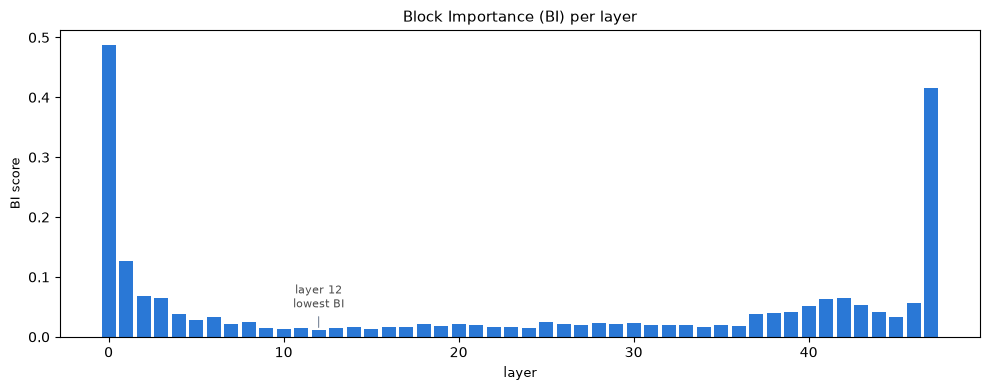

In [4]:
from bonsai.importance.viz import plot_layer_importance

fig = plot_layer_importance(depth_scores)
fig.savefig(f"{RUN_DIR}/depth_bar.png", dpi=150)

lowest = int(depth_scores.argmin())
highest = int(depth_scores.argmax())
print(f"lowest BI:  layer {lowest} ({depth_scores[lowest]:.4f}) -- closest to a no-op")
print(f"highest BI: layer {highest} ({depth_scores[highest]:.4f}) -- transforms its input the most")

## Do the three scoring methods agree?

The three plots above each show one axis in isolation. Heads and experts are
both activation-magnitude formulas; BI is a completely different
computation (cosine distance, not magnitude at all). If all three still
land on the same "early and late layers matter most" shape, that's a real
signal the pattern is about the model, not an artifact of any one formula.

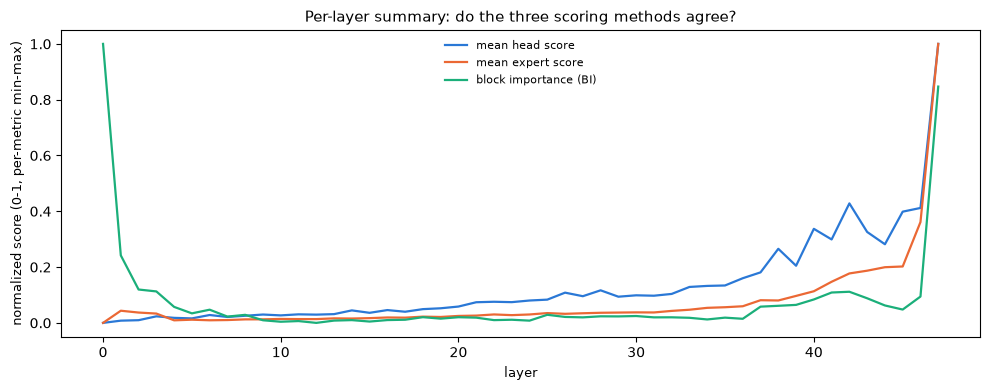

In [5]:
from bonsai.importance.viz import plot_layer_summary

fig = plot_layer_summary(head_scores, expert_scores, depth_scores)
fig.savefig(f"{RUN_DIR}/layer_summary.png", dpi=150)

## Score distributions

The heatmaps above clip their color scale at the 95th percentile -- this is
why: both distributions are extremely long-tailed, on a log scale, not just
"a bit skewed." A linear color scale to the true max would have shown one
bright cell and 6,000+ indistinguishable pale ones.

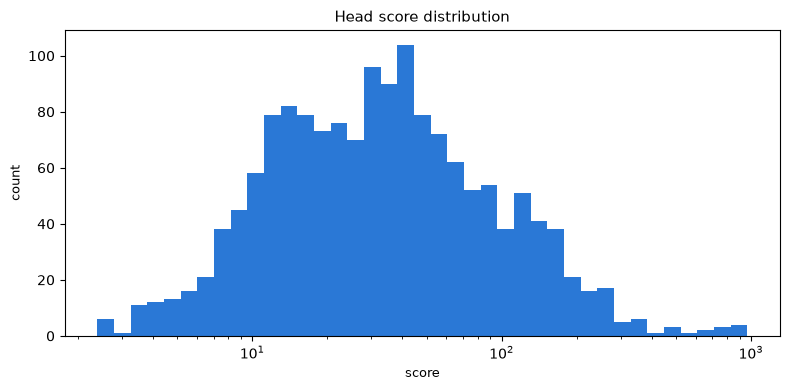

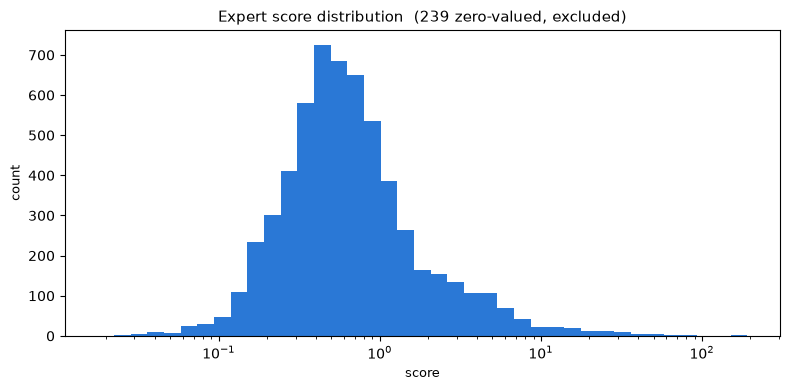

In [6]:
from bonsai.importance.viz import plot_score_distribution

fig = plot_score_distribution(head_scores, title="Head score distribution", xlabel="score")
fig.savefig(f"{RUN_DIR}/head_distribution.png", dpi=150)

fig = plot_score_distribution(expert_scores, title="Expert score distribution", xlabel="score")
fig.savefig(f"{RUN_DIR}/expert_distribution.png", dpi=150)

## Expert concentration -- a signal for how aggressively 2.3 could prune

For each layer, sort its 128 experts by score and plot the cumulative share
of that layer's total importance captured as more experts are kept. A curve
hugging the diagonal means importance is spread evenly (pruning any expert
hurts about equally); a curve bowing sharply toward the top-left means a
small subset of experts already carries most of the importance -- exactly
the situation where aggressive expert pruning should cost the least.

on average across layers, the top 20 of 128 experts (~16%) capture 33% of total importance


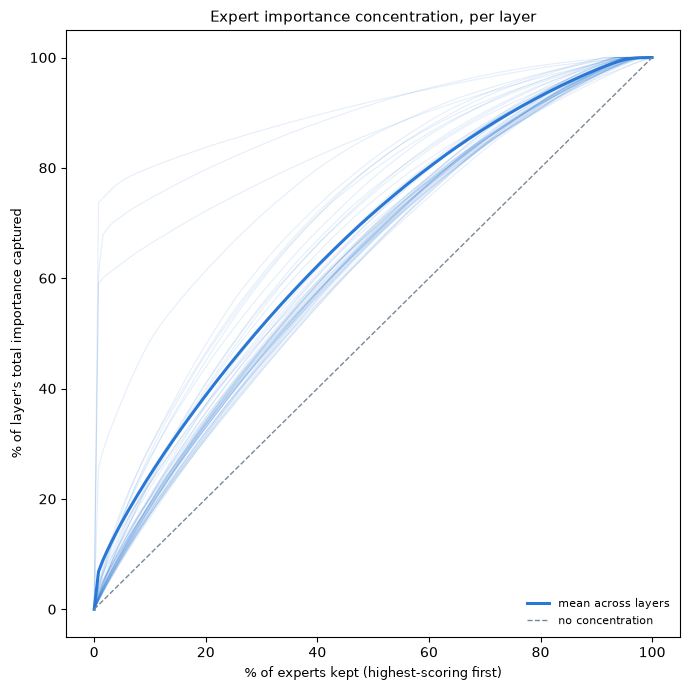

In [7]:
from bonsai.importance.viz import plot_expert_concentration

fig = plot_expert_concentration(expert_scores)
fig.savefig(f"{RUN_DIR}/expert_concentration.png", dpi=150)

sorted_scores, _ = torch.sort(expert_scores, dim=1, descending=True)
cum_share = sorted_scores.cumsum(dim=1) / sorted_scores.sum(dim=1, keepdim=True).clamp(min=1e-12)
top20_share = cum_share[:, 19].mean()  # 20 of 128 experts = ~16%
print(
    f"on average across layers, the top 20 of 128 experts (~16%) capture {top20_share:.0%} of total importance"
)

## Grounding it in the real architecture

The heatmaps above are abstract matrices -- rows and columns, no sense of
what expert 92 physically *is*. This is the same expert-grid layout
`00_model_architecture.ipynb` draws (one box per expert, wrapped at 16
columns), colored by layer 2's real importance scores instead of the
earlier notebook's illustrative binary highlighting. Expert 92 -- one of
the three known Super Experts -- should be the one bright square.

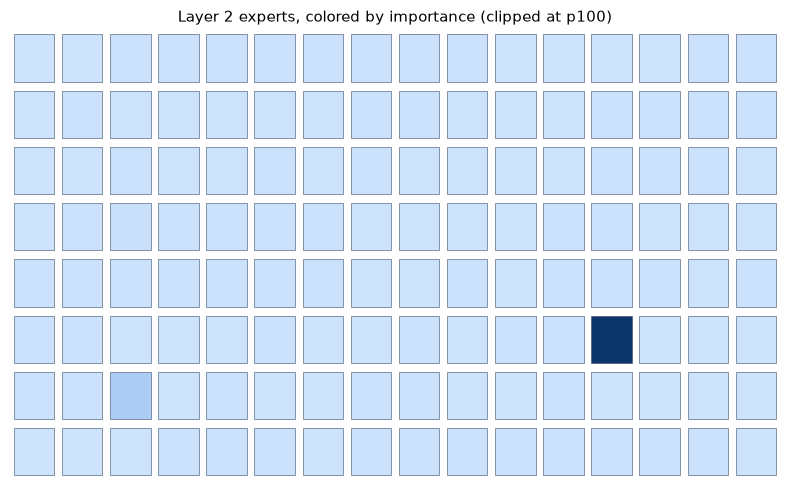

In [8]:
from bonsai.architecture import summarize
from bonsai.config import load_config
from bonsai.importance.viz import plot_expert_grid_for_layer

config = load_config("../configs/qwen3-30b-a3b.toml")
summary = summarize(config.model.repo_id, revision=config.model.revision)

fig = plot_expert_grid_for_layer(summary, expert_scores[2], layer_idx=2)
fig.savefig(f"{RUN_DIR}/expert_grid_layer2.png", dpi=150)

## Summary: what does the model actually do with TypeScript code?

Plain-language version of everything above -- no pruning has happened yet,
this is just what the real data shows about how the unpruned model behaves.
Each point below has a cropped visual straight from the real data (or the
architecture diagram) underneath it, pointing at exactly what to look at.

### 1. The first and last layers matter the most

The very first layer does the heaviest lifting (turning raw tokens into
something the rest of the model can use), and the very last layer is doing
something just as intense right before the model predicts a token.
Everything in between looks comparatively lighter and more redundant --
true for attention heads, experts, and the BI depth signal alike.

Cropped from the architecture diagram above (00_model_architecture.ipynb):
every one of the 48 decoder layers shares this exact internal structure --
the real attention-head count and the full 128-expert grid. Layer 0 is the
first repetition of this block, layer 47 the last -- the two layers whose
scores spike hardest in the charts above.


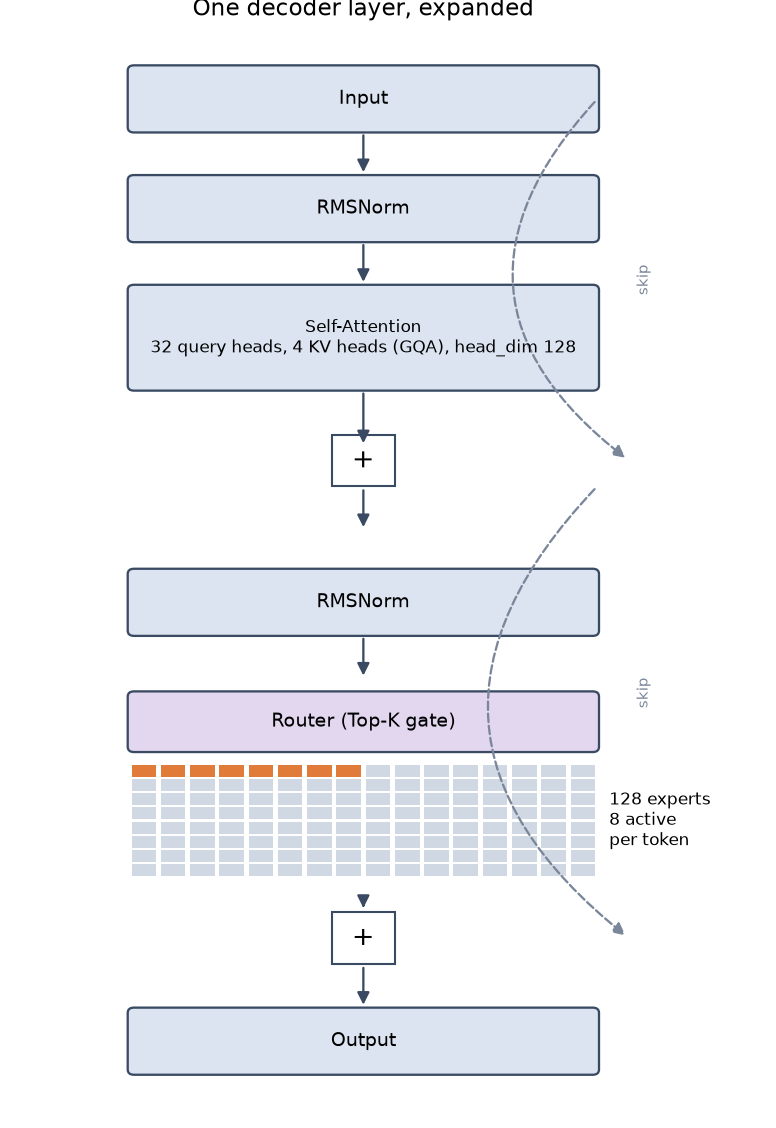

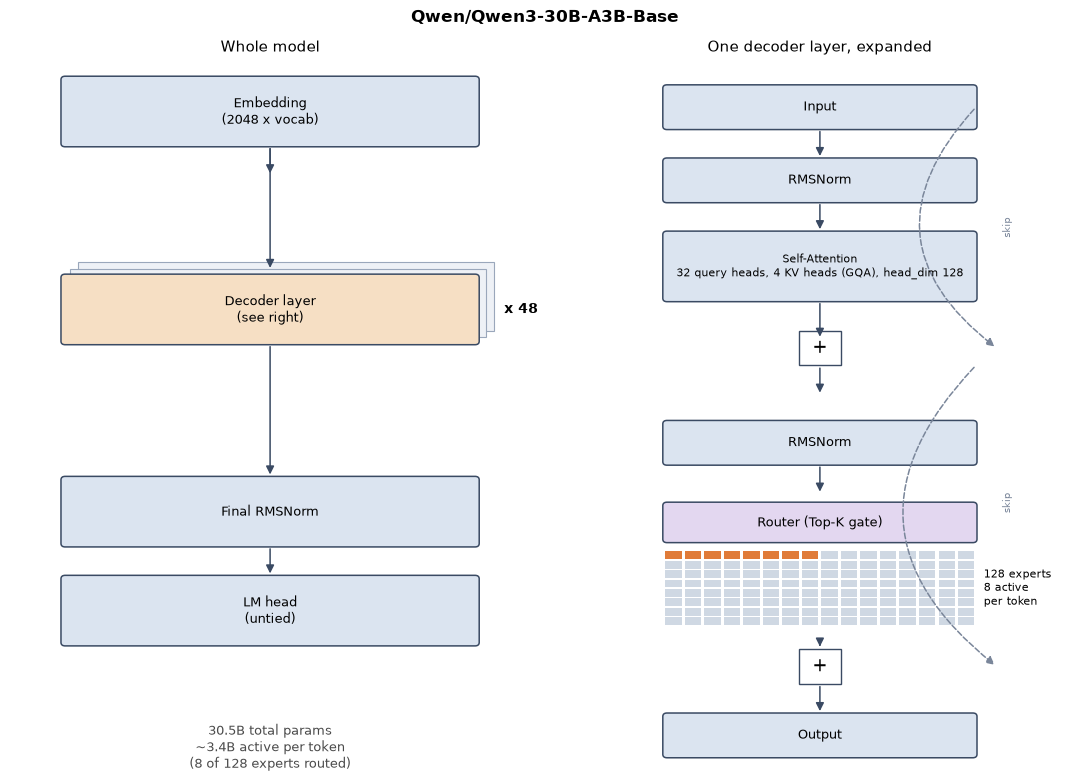

In [9]:
from PIL import Image

from bonsai.architecture.viz import plot_architecture

arch_fig = plot_architecture(summary)
arch_fig.savefig(f"{RUN_DIR}/_arch_full.png", dpi=150)

img = Image.open(f"{RUN_DIR}/_arch_full.png")
w, h = img.size
layer_detail_crop = img.crop((int(w * 0.53), int(h * 0.06), w, h))
layer_detail_crop.save(f"{RUN_DIR}/architecture_layer_detail.png")

print("Cropped from the architecture diagram above (00_model_architecture.ipynb):")
print("every one of the 48 decoder layers shares this exact internal structure --")
print("the real attention-head count and the full 128-expert grid. Layer 0 is the")
print("first repetition of this block, layer 47 the last -- the two layers whose")
print("scores spike hardest in the charts above.")
layer_detail_crop

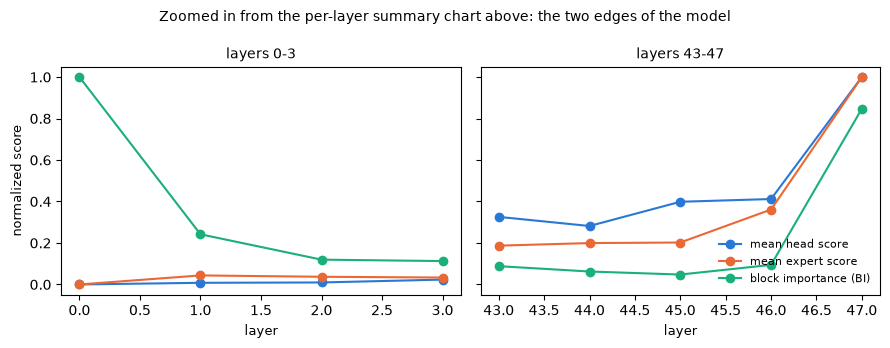

In [10]:
import matplotlib.pyplot as plt


def normalize(x: torch.Tensor) -> torch.Tensor:
    lo, hi = x.min(), x.max()
    return (x - lo) / (hi - lo + 1e-12)


mean_head = normalize(head_scores.mean(dim=1))
mean_expert = normalize(expert_scores.mean(dim=1))
bi = normalize(depth_scores)

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, (lo, hi), title in [(left, (0, 4), "layers 0-3"), (right, (43, 48), "layers 43-47")]:
    layers = range(lo, hi)
    ax.plot(layers, mean_head[lo:hi], color="#2a78d6", marker="o", label="mean head score")
    ax.plot(layers, mean_expert[lo:hi], color="#eb6834", marker="o", label="mean expert score")
    ax.plot(layers, bi[lo:hi], color="#1baf7a", marker="o", label="block importance (BI)")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("layer", fontsize=9)
left.set_ylabel("normalized score", fontsize=9)
right.legend(fontsize=8, frameon=False, loc="lower right")
fig.suptitle(
    "Zoomed in from the per-layer summary chart above: the two edges of the model", fontsize=10
)
fig.tight_layout()
fig.savefig(f"{RUN_DIR}/layer_summary_edges_zoom.png", dpi=150)

### 2. Three specific experts are doing something unusual

Out of 128 experts per layer, three of them (in layers 1, 2, and 3) are
dramatically bigger than every other expert anywhere in the model -- not a
little bigger, tens of times bigger. These match "Super Experts" already
reported for this exact model by outside research (arXiv 2507.23279), so
this isn't specific to our TypeScript data -- it looks like a real,
structural feature of the model itself. Below is each layer's real expert
grid (the same schematic layout `00_model_architecture.ipynb` draws, colored
by real scores here instead) -- one clearly bright square in each.

layer 1: expert 68, score 78.22 -- the one dark square below


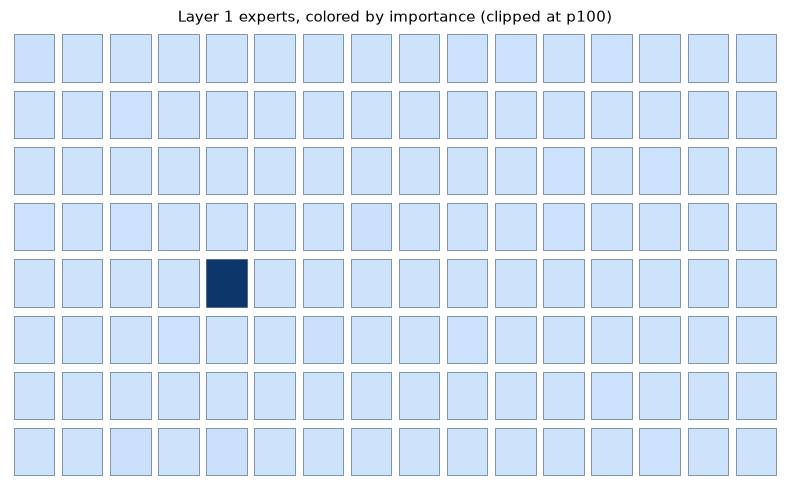

In [11]:
from bonsai.importance.viz import plot_expert_grid_for_layer

layer, expert = 1, 68
print(
    f"layer {layer}: expert {expert}, score {expert_scores[layer, expert]:.2f} -- the one dark square below"
)
fig = plot_expert_grid_for_layer(summary, expert_scores[layer], layer_idx=layer)
fig.savefig(f"{RUN_DIR}/expert_grid_layer{layer}.png", dpi=150)

layer 2: expert 92, score 56.44 -- the one dark square below


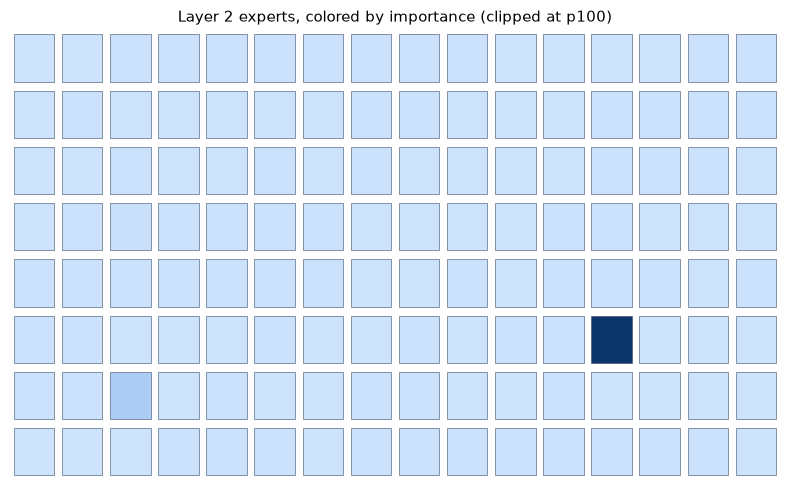

In [12]:
layer, expert = 2, 92
print(
    f"layer {layer}: expert {expert}, score {expert_scores[layer, expert]:.2f} -- the one dark square below"
)
fig = plot_expert_grid_for_layer(summary, expert_scores[layer], layer_idx=layer)
fig.savefig(f"{RUN_DIR}/expert_grid_layer{layer}.png", dpi=150)

layer 3: expert 82, score 50.62 -- the one dark square below


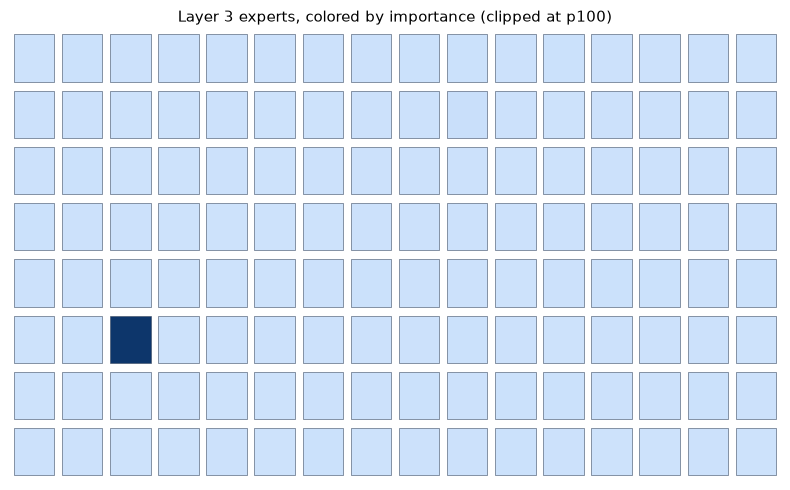

In [13]:
layer, expert = 3, 82
print(
    f"layer {layer}: expert {expert}, score {expert_scores[layer, expert]:.2f} -- the one dark square below"
)
fig = plot_expert_grid_for_layer(summary, expert_scores[layer], layer_idx=layer)
fig.savefig(f"{RUN_DIR}/expert_grid_layer{layer}.png", dpi=150)

### 3. Most experts look somewhat redundant

On average, a layer's top ~16% of experts (about 20 of 128) already account
for a third of that layer's total importance. That's a real signal there's
room to prune a lot of experts without losing much -- as long as the
handful of standouts above are left alone. Below is the concentration curve
from earlier, zoomed in and marked at exactly that point.

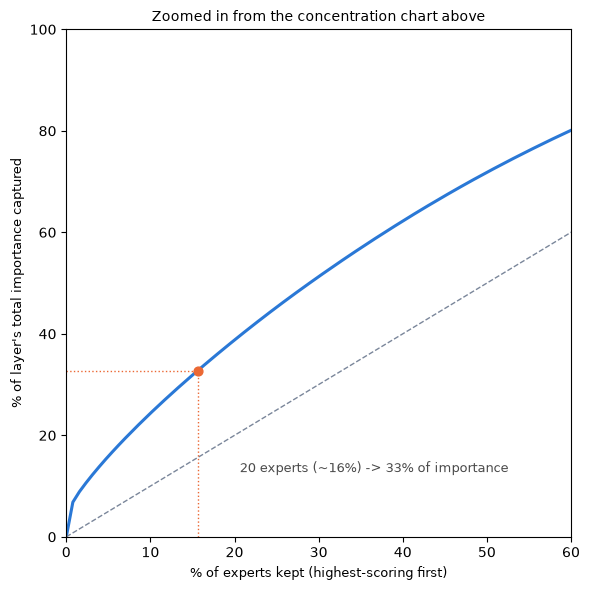

In [14]:
fig, ax = plt.subplots(figsize=(6, 6))
sorted_scores, _ = torch.sort(expert_scores, dim=1, descending=True)
cum_share_all = (
    sorted_scores.cumsum(dim=1) / sorted_scores.sum(dim=1, keepdim=True).clamp(min=1e-12) * 100
)
x_pct = torch.linspace(0, 100, expert_scores.shape[1] + 1)
mean_curve = torch.cat([torch.zeros(1), cum_share_all.mean(dim=0)])

ax.plot(x_pct, mean_curve, color="#2a78d6", linewidth=2.2)
ax.plot([0, 100], [0, 100], color="#7a869a", linewidth=1.0, linestyle="--")

mark_x = 20 / 128 * 100
mark_y = float(top20_share) * 100
ax.plot([mark_x, mark_x], [0, mark_y], color="#eb6834", linewidth=1.0, linestyle=":")
ax.plot([0, mark_x], [mark_y, mark_y], color="#eb6834", linewidth=1.0, linestyle=":")
ax.scatter([mark_x], [mark_y], color="#eb6834", zorder=5, s=40)
ax.annotate(
    f"20 experts (~16%) -> {mark_y:.0f}% of importance",
    xy=(mark_x, mark_y),
    xytext=(mark_x + 5, mark_y - 20),
    fontsize=9,
    color="#4a4a4a",
)

ax.set_xlim(0, 60)
ax.set_ylim(0, 100)
ax.set_title("Zoomed in from the concentration chart above", fontsize=10)
ax.set_xlabel("% of experts kept (highest-scoring first)", fontsize=9)
ax.set_ylabel("% of layer's total importance captured", fontsize=9)
fig.tight_layout()
fig.savefig(f"{RUN_DIR}/expert_concentration_zoom.png", dpi=150)

### 4. The three scoring methods mostly agree, with one interesting exception

Attention-head and expert magnitude tell basically the same story:
redundant in the middle, intense at both edges (see the zoomed edges
above). Block Importance -- which measures how much a layer changes its
input, not magnitude at all -- agrees at the very first and last layers,
but tells a flatter, noisier story through the middle third of the model.
Below is that middle region zoomed in: notice BI (green) barely moves while
the two magnitude-based scores (blue, orange) keep climbing.

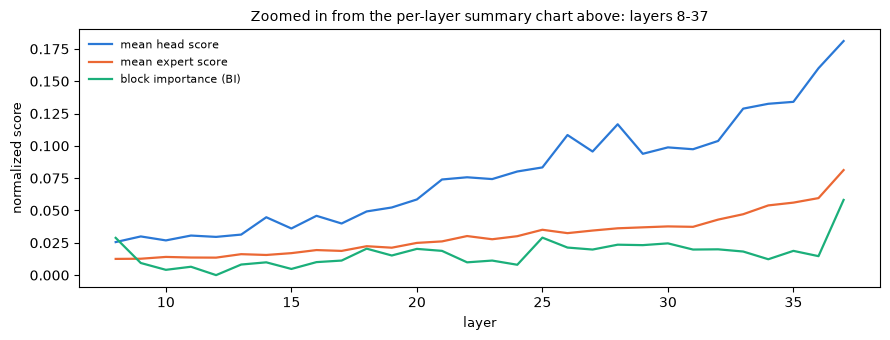

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.5))
lo, hi = 8, 38
layers = range(lo, hi)
ax.plot(layers, mean_head[lo:hi], color="#2a78d6", linewidth=1.6, label="mean head score")
ax.plot(layers, mean_expert[lo:hi], color="#eb6834", linewidth=1.6, label="mean expert score")
ax.plot(layers, bi[lo:hi], color="#1baf7a", linewidth=1.6, label="block importance (BI)")
ax.set_title("Zoomed in from the per-layer summary chart above: layers 8-37", fontsize=10)
ax.set_xlabel("layer", fontsize=9)
ax.set_ylabel("normalized score", fontsize=9)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(f"{RUN_DIR}/layer_summary_middle_zoom.png", dpi=150)

**What this means for pruning next (Phase 2):** nothing has been pruned
yet -- everything above is what the unpruned model looks like. But the
shape of these results already points at where pruning is likely safe (the
redundant middle layers, most ordinary experts) and where it's clearly
risky (the first/last layers, the three Super Experts), before a single
real pruning experiment has run.